# EDA + Preprocessing: MSMD (Multimodal Sheet Music Dataset)

**Proyek:** Pencocokan gambar partitur dan audio musik (skor kemiripan)

Notebook ini menggabungkan:
1. Pemahaman dataset (sumber, jumlah, fitur, label, distribusi, karakteristik)
2. Audit kualitas data dan potensi leakage
3. Pemilihan subset 25 piece + split group-level
4. Eksperimen preprocessing sampai ditemukan konfigurasi yang dipakai
5. Pembuatan artefak NumPy yang siap dipakai training

Dataset: `msmd_aug_v1-1_no-audio` (MSMD augmented v1.1, tanpa file audio mentah).

## 1. Metodologi Dataset (ringkas)

**Sumber.** MSMD (Dorfer et al., 2018) adalah dataset sintetis partitur-audio untuk piano klasik. Versi yang dipakai adalah varian *augmented* `msmd_aug_v1-1_no-audio`, yang hanya menyimpan fitur turunan audio (spektrogram, piano roll, daftar note) dan **tidak** menyimpan file `.flac/.wav`.

**Struktur.** Setiap piece memiliki:
- sumber LilyPond + MIDI + `meta.yml`
- `scores/<piece>_ly/` berisi PDF, gambar halaman (`img/*.png`), koordinat (`coords/*.npy`), dan notasi graph + alignment (`mung/*.xml`)
- `performances/<piece>_tempo-XXX_<soundfont>/` berisi MIDI performa dan 5 fitur `.npy`

**Modalitas.**
- Visual: gambar halaman partitur (PNG, RGBA, 835x1181 atau 835x1080)
- Audio: `spec.npy` (92 bin log-filterbank x frame, 20 fps), `midi.npy` (128 pitch x frame), `notes.npy` (onset, pitch, durasi, velocity, voice)

**Label/target.** Dataset tidak menyediakan kolom target eksplisit. Target diturunkan dari struktur folder:
- `piece_id` sebagai kelas utama (600 piece lengkap)
- `composer` sebagai label sekunder
- label biner pasangan: `1` jika partitur dan audio berasal dari piece yang sama, `0` jika berbeda

**Karakteristik penting.** Frame rate 20 fps; `onsets`/`durations` dalam frame; koordinat `coords` memakai `(y, x)` dan tidak lengkap; `bars_*.npy` kosong; 15 performance per piece bukan sampel independen; terdapat varian karya yang mirip (mis. `-a4` vs `-let`).

**Catatan penting:** pasangan positif pada tahap ini bersifat **piece-level** ? halaman partitur piece X dipasangkan dengan segmen audio mana pun dari piece X. Ini belum merupakan alignment temporal note-per-note.

In [1]:
import os
import re
import json
import random
import warnings
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import yaml
from PIL import Image

import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT = Path(r"C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT")
BASE = PROJECT / "msmd_aug_v1-1_no-audio"
DATA = PROJECT / "data"
PROC = DATA / "processed"
FIG = PROJECT / "reports" / "figures"
REP = PROJECT / "reports"
for d in [DATA, PROC, FIG, REP]:
    d.mkdir(parents=True, exist_ok=True)

FPS = 20
IMG_SIZE = 384
SEG_FRAMES = 100
N_SUBSET = 25
N_PERF = 4
PAIRS_PER_PAGE = 8

stats = {}
print("Project :", PROJECT)
print("Dataset :", BASE, "| exists:", BASE.exists())
print("Output  :", PROC)

Project : C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT
Dataset : C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT\msmd_aug_v1-1_no-audio | exists: True
Output  : C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT\data\processed


## 2. Inventory Dataset
Scan seluruh 697 folder piece: jumlah halaman, performance, ketersediaan MuNG/koordinat/fitur, dan statistik `meta.yml`.

In [2]:
PERF_RE = re.compile(r"^(?P<piece>.+)_tempo-(?P<tempo>\d+)_(?P<sfont>.+)$")
FEAT_SUFFIXES = ["notes", "onsets", "durations", "midi", "spec"]


def parse_piece(name):
    parts = name.split("__")
    if len(parts) >= 3:
        return parts[0], parts[1], "__".join(parts[2:])
    return name, "", ""


VARIANT_TOKENS = ["a4", "letter", "let", "midi", "ps", "wfi", "wfp"]


def make_work_key(comp, coll, piece):
    tokens = re.split(r"[^a-z0-9]+", piece.lower())
    tokens = ["chop" if t == "chp" else t for t in tokens]
    tokens = [t for t in tokens if t not in VARIANT_TOKENS]
    if tokens and tokens[-1] == "i":
        tokens = tokens[:-1]
    s = "".join(tokens)
    s = re.sub(r"\d+", lambda m: str(int(m.group())), s)
    return f"{comp}__{coll}__{s}"


piece_rows = []
perf_rows = []
all_pngs = []

piece_dirs = sorted([d for d in BASE.iterdir() if d.is_dir()])
for pdir in piece_dirs:
    comp, coll, piece = parse_piece(pdir.name)
    wk = make_work_key(comp, coll, piece)

    score_dirs = [d for d in (pdir / "scores").iterdir() if d.is_dir()] if (pdir / "scores").is_dir() else []
    n_pages = n_mung = n_pdf = n_coords = 0
    for sd in score_dirs:
        pngs = sorted((sd / "img").glob("*.png")) if (sd / "img").is_dir() else []
        mungs = sorted((sd / "mung").glob("*.xml")) if (sd / "mung").is_dir() else []
        pdfs = list(sd.glob("*.pdf"))
        coords = list((sd / "coords").glob("*.npy")) if (sd / "coords").is_dir() else []
        n_pages += len(pngs)
        n_mung += len(mungs)
        n_pdf += len(pdfs)
        n_coords += len(coords)
        all_pngs.extend([str(x) for x in pngs])

    perf_dirs = [d for d in (pdir / "performances").iterdir() if d.is_dir()] if (pdir / "performances").is_dir() else []
    piece_perf_complete = []
    for perf_d in perf_dirs:
        m = PERF_RE.match(perf_d.name)
        tempo = int(m.group("tempo")) if m else None
        sfont = m.group("sfont") if m else ""
        feat_dir = perf_d / "features"
        n_feat = sum((feat_dir / f"{perf_d.name}.flac_{s}.npy").exists() for s in FEAT_SUFFIXES) if feat_dir.is_dir() else 0
        has_midi = (perf_d / f"{perf_d.name}.midi").exists()
        perf_rows.append({
            "piece": pdir.name,
            "composer": comp,
            "collection": coll,
            "work_group": wk,
            "perf_name": perf_d.name,
            "perf_dir": str(perf_d),
            "features_dir": str(feat_dir),
            "tempo": tempo,
            "soundfont": sfont,
            "n_feat": n_feat,
            "complete_features": n_feat == len(FEAT_SUFFIXES),
            "has_midi": has_midi,
        })
        if n_feat == len(FEAT_SUFFIXES):
            piece_perf_complete.append((perf_d.name, tempo, sfont, feat_dir))

    meta = {}
    if (pdir / "meta.yml").exists():
        try:
            meta = yaml.safe_load((pdir / "meta.yml").read_text(encoding="utf-8")) or {}
        except Exception:
            meta = {}

    aln = meta.get("aln_piece_stats") or {}
    if isinstance(aln, list):
        aln = aln[0] if aln else {}
    n_events = aln.get("n_events")
    aln_errors = None
    if n_events:
        aln_errors = (
            aln.get("n_mungos_aligned_wrong_pitch", 0)
            + aln.get("n_mungos_not_aligned_not_tied", 0)
            + aln.get("n_events_without_corresponding_mungo", 0)
        ) / n_events

    n_notes = None
    dur_s = None
    if piece_perf_complete:
        canon = sorted(
            piece_perf_complete,
            key=lambda x: (abs((x[1] or 1000) - 1000), 0 if x[2] == "grand-piano-YDP-20160804" else 1),
        )[0]
        try:
            notes = np.load(Path(canon[3]) / f"{canon[0]}.flac_notes.npy")
            n_notes = int(notes.shape[0])
            dur_s = float(notes[:, 0].max() + notes[:, 2].max()) if len(notes) else 0.0
        except Exception:
            pass

    piece_rows.append({
        "piece": pdir.name,
        "composer": comp,
        "collection": coll,
        "work_group": wk,
        "n_scores": len(score_dirs),
        "pages": n_pages,
        "n_mung": n_mung,
        "n_pdf": n_pdf,
        "n_coords": n_coords,
        "n_performances": len(perf_dirs),
        "n_features_complete": len(piece_perf_complete),
        "has_mung": n_mung > 0,
        "has_coords": n_coords > 0,
        "meta_present": bool(meta),
        "aligned_well": meta.get("aligned_well"),
        "processed": meta.get("processed"),
        "n_events": n_events,
        "alignment_error_rate": aln_errors,
        "n_notes_canonical": n_notes,
        "duration_s_canonical": dur_s,
    })

manifest = pd.DataFrame(piece_rows)
perf_df = pd.DataFrame(perf_rows)
manifest.to_csv(DATA / "manifest_all_pieces.csv", index=False)
perf_df.to_csv(DATA / "performance_manifest.csv", index=False)

print(f"Piece folders            : {len(manifest)}")
print(f"Performance folders      : {len(perf_df)}")
print(f"Performance with 5 feats : {int(perf_df.complete_features.sum())}")
print(f"Score page PNGs          : {len(all_pngs)}")
display(manifest.head(5))

Piece folders            : 697
Performance folders      : 9015
Performance with 5 feats : 9000
Score page PNGs          : 2041


,piece,composer,collection,work_group,n_scores,pages,n_mung,n_pdf,n_coords,n_performances,n_features_complete,has_mung,has_coords,meta_present,aligned_well,processed,n_events,alignment_error_rate,n_notes_canonical,duration_s_canonical
0,AdamA__giselle__giselle,AdamA,giselle,AdamA__giselle__giselle,1,2,2,1,6,15,15,True,True,True,False,False,541.0,0.0,541.0,72.000000
1,AlbenizIMF__O71__Rumores_de_la-caleta,AlbenizIMF,O71,AlbenizIMF__O71__rumoresdelacaleta,0,0,0,0,0,0,0,False,False,True,False,False,NaN,NaN,NaN,NaN
2,AndreJ__O34__andre-sonatine,AndreJ,O34,AndreJ__O34__andresonatine,1,2,2,1,6,15,15,True,True,True,False,False,571.0,0.0,571.0,96.346141
3,Anonymous__lanative__lanative,Anonymous,lanative,Anonymous__lanative__lanative,1,1,1,1,3,15,15,True,True,True,False,False,173.0,0.0,173.0,31.977990
4,Anonymous__lesgraces__lesgraces,Anonymous,lesgraces,Anonymous__lesgraces__lesgraces,1,1,1,1,3,15,15,True,True,True,False,False,228.0,0.0,228.0,42.209216


## 3. Kelengkapan Data dan Definisi Label
Memisahkan piece lengkap, score-only, performance-only, dan yang tidak punya keduanya. Bagian ini juga menegaskan bahwa label diturunkan dari struktur folder.

In [3]:
has_score = manifest["n_scores"] > 0
has_perf = manifest["n_performances"] > 0
has_feat = manifest["n_features_complete"] > 0

completeness = pd.DataFrame([
    {"kategori": "Total folder piece", "jumlah": len(manifest)},
    {"kategori": "Punya score", "jumlah": int(has_score.sum())},
    {"kategori": "Punya performance", "jumlah": int(has_perf.sum())},
    {"kategori": "Punya score + performance", "jumlah": int((has_score & has_perf).sum())},
    {"kategori": "Punya fitur lengkap (5 npy)", "jumlah": int(has_feat.sum())},
    {"kategori": "Siap dipakai (score + fitur lengkap)", "jumlah": int((has_score & has_feat).sum())},
    {"kategori": "Score-only (tanpa performance)", "jumlah": int((has_score & ~has_perf).sum())},
    {"kategori": "Performance-only (tanpa score)", "jumlah": int((~has_score & has_perf).sum())},
    {"kategori": "Tidak punya keduanya", "jumlah": int((~has_score & ~has_perf).sum())},
    {"kategori": "Score tanpa MuNG", "jumlah": int((has_score & ~manifest["has_mung"]).sum())},
    {"kategori": "meta.yml tanpa statistik alignment", "jumlah": int((manifest["meta_present"] & manifest["n_events"].isna()).sum())},
    {"kategori": "aligned_well == True", "jumlah": int((manifest["aligned_well"] == True).sum())},
    {"kategori": "processed == True", "jumlah": int((manifest["processed"] == True).sum())},
])
display(completeness)

print("Contoh piece score-only:")
display(manifest[has_score & ~has_perf][["piece", "pages", "n_performances"]].head(8))

print("Contoh piece tanpa score/performance:")
display(manifest[~has_score & ~has_perf][["piece", "pages", "n_performances"]].head(8))

stats["n_total_pieces"] = int(len(manifest))
stats["n_score_pieces"] = int(has_score.sum())
stats["n_perf_pieces"] = int(has_perf.sum())
stats["n_both_pieces"] = int((has_score & has_perf).sum())
stats["n_ready_pieces"] = int((has_score & has_feat).sum())
stats["n_perf_dirs"] = int(len(perf_df))
stats["n_complete_perfs"] = int(perf_df.complete_features.sum())
stats["n_pages"] = int(len(all_pngs))
stats["n_composers"] = int(manifest.composer.nunique())
stats["n_work_groups"] = int(manifest.work_group.nunique())

,kategori,jumlah
0,Total folder piece,697
1,Punya score,654
2,Punya performance,601
3,Punya score + performance,601
4,Punya fitur lengkap (5 npy),600
5,Siap dipakai (score + fitur lengkap),600
6,Score-only (tanpa performance),53
7,Performance-only (tanpa score),0
8,Tidak punya keduanya,43
9,Score tanpa MuNG,61


Contoh piece score-only:


,piece,pages,n_performances
21,BachJS__BWV1080__score,9,0
25,BachJS__BWV347__bwv347,1,0
57,BachJS__BWV796__bwv796,2,0
61,BachJS__BWV800__bwv800,2,0
63,BachJS__BWV802__Bach-Duet1,5,0
65,BachJS__BWV805__Bach-Duet4,4,0
67,BachJS__BWV806__bach-english-suite-1-bourree-2,2,0
72,BachJS__BWV814__bach-french-suite-3-courante,2,0


Contoh piece tanpa score/performance:


,piece,pages,n_performances
1,AlbenizIMF__O71__Rumores_de_la-caleta,0,0
87,BachJS__BWV817__bach-french-suite-6-courante,0,0
159,BachJS__BWV903__bwv903fan,0,0
161,BachJS__BWV910__bwv910,0,0
228,BeethovenLv__O2__beethoven-op2-no1-adagio,0,0
260,BurgmullerJFF__O100__25EF-01,0,0
278,BurgmullerJFF__ploermel__ploermel,0,0
280,ChopinFF__O10__10-02-i,0,0


## 4. Distribusi dan Karakteristik Dataset
Distribusi dihitung dari seluruh metadata piece/performance, sedangkan statistik isi array diambil dari sampel 1.200 performance (cukup representatif dan tidak membebani memori).

In [4]:
rng = np.random.default_rng(SEED)
complete_perfs = perf_df[perf_df["complete_features"]].reset_index(drop=True)
sample_n = min(1200, len(complete_perfs))
sample_perfs = complete_perfs.iloc[rng.choice(len(complete_perfs), size=sample_n, replace=False)]

qrows = []
pitch_hist_total = np.zeros(128, dtype=np.int64)
vel_hist_total = np.zeros(128, dtype=np.int64)

for _, r in sample_perfs.iterrows():
    fd = Path(r["features_dir"])
    name = r["perf_name"]
    try:
        notes = np.load(fd / f"{name}.flac_notes.npy")
        spec = np.load(fd / f"{name}.flac_spec.npy")
    except Exception:
        continue
    if len(notes) == 0:
        continue
    dur = float(notes[:, 0].max() + notes[:, 2].max())
    ph = np.bincount(notes[:, 1].astype(int), minlength=128)
    vh = np.bincount(np.clip(notes[:, 3].astype(int), 0, 127), minlength=128)
    pitch_hist_total += ph
    vel_hist_total += vh
    qrows.append({
        "piece": r["piece"],
        "perf_name": name,
        "tempo": r["tempo"],
        "soundfont": r["soundfont"],
        "n_notes": int(len(notes)),
        "duration_s": dur,
        "n_frames": int(spec.shape[1]),
        "spec_bins": int(spec.shape[0]),
        "pitch_min": int(notes[:, 1].min()),
        "pitch_max": int(notes[:, 1].max()),
        "vel_mean": float(notes[:, 3].mean()),
        "n_voices": int(len(np.unique(notes[:, 4]))),
        "spec_min": float(spec.min()),
        "spec_max": float(spec.max()),
        "spec_mean": float(spec.mean()),
        "spec_std": float(spec.std()),
    })

perf_stats = pd.DataFrame(qrows)
perf_stats.to_csv(DATA / "perf_sampled_stats.csv", index=False)
print("Performance dianalisis:", len(perf_stats))
display(perf_stats.describe().T)

Performance dianalisis: 1200


,count,mean,std,min,25%,50%,75%,max
tempo,1200.0,1122.291667,371.886517,500.000000,950.000000,1000.000000,1250.000000,2000.000000
n_notes,1200.0,866.350000,926.510172,58.000000,281.000000,567.500000,1158.000000,6265.000000
duration_s,1200.0,141.151443,150.297395,6.818175,47.961194,91.837449,175.477786,1130.000000
n_frames,1200.0,2786.105833,2986.253558,123.000000,937.000000,1806.500000,3460.000000,22591.000000
spec_bins,1200.0,92.000000,0.000000,92.000000,92.000000,92.000000,92.000000,92.000000
pitch_min,1200.0,35.884167,7.109116,3.000000,31.000000,36.000000,40.000000,57.000000
pitch_max,1200.0,85.782500,6.651972,66.000000,82.000000,84.000000,89.000000,111.000000
vel_mean,1200.0,64.000000,0.000000,64.000000,64.000000,64.000000,64.000000,64.000000
n_voices,1200.0,2.062500,0.402569,1.000000,2.000000,2.000000,2.000000,6.000000
spec_min,1200.0,0.000022,0.000045,0.000000,0.000000,0.000007,0.000022,0.000866


In [5]:
img_sample = list(rng.choice(all_pngs, size=min(300, len(all_pngs)), replace=False))
img_rows = []
for p in img_sample:
    im = Image.open(p)
    arr = np.asarray(im.convert("RGBA"))
    alpha = arr[..., 3:4].astype(np.float32) / 255.0
    rgb = arr[..., :3].astype(np.float32)
    gray = 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]
    gray = gray * alpha[..., 0] + 255 * (1 - alpha[..., 0])
    img_rows.append({
        "path": p,
        "mode": im.mode,
        "width": im.size[0],
        "height": im.size[1],
        "aspect": im.size[0] / im.size[1],
        "ink_ratio": float((gray < 128).mean()),
    })
img_stats = pd.DataFrame(img_rows)
img_stats.to_csv(DATA / "image_sampled_stats.csv", index=False)
display(img_stats.groupby(["mode", "width", "height"]).size().rename("count").reset_index())
print(img_stats[["aspect", "ink_ratio"]].describe().T)

,mode,width,height,count
0,RGBA,835,1080,8
1,RGBA,835,1181,292


           count      mean       std       min       25%       50%       75%       max
aspect     300.0  0.708791  0.010670  0.707028  0.707028  0.707028  0.707028  0.773148
ink_ratio  300.0  0.085135  0.025138  0.017439  0.071362  0.088358  0.103494  0.147433


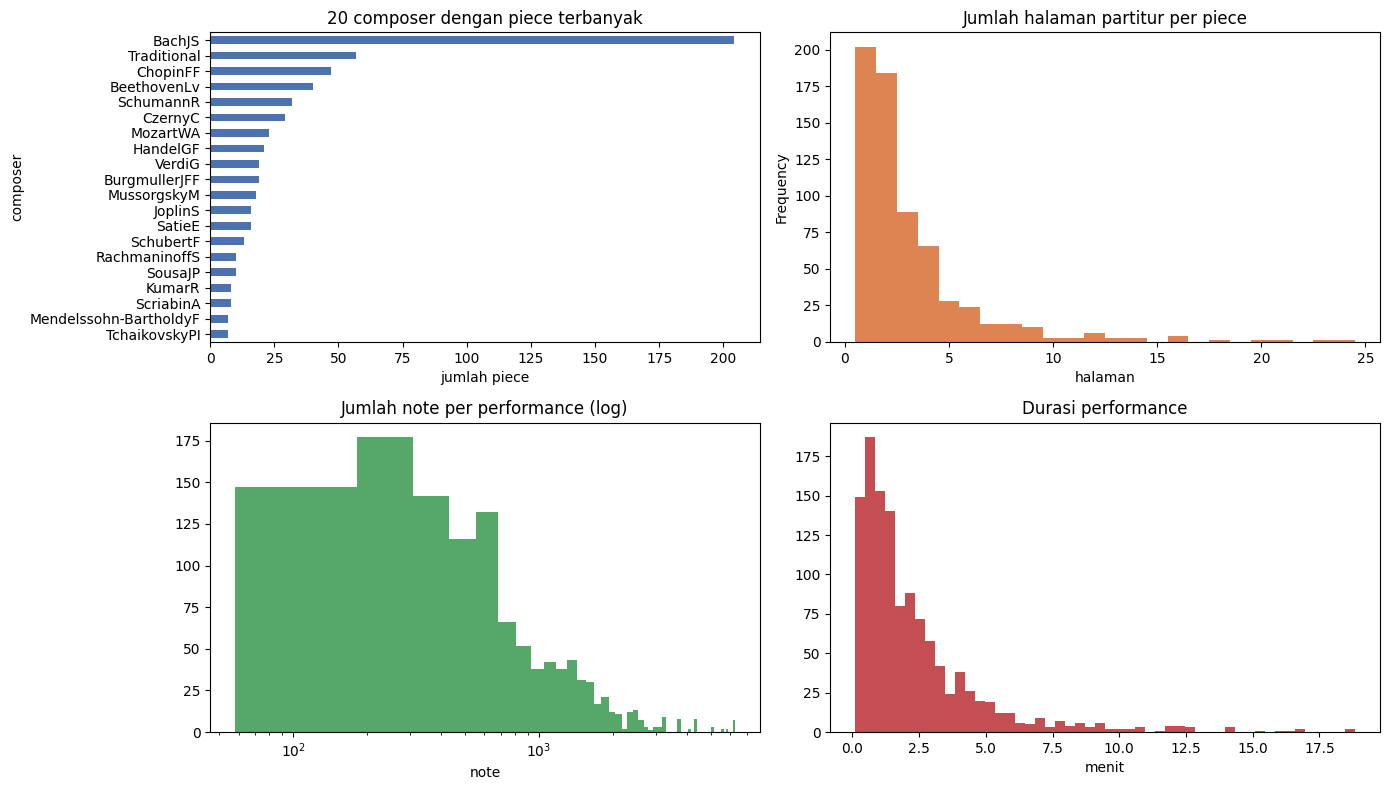

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

manifest["composer"].value_counts().head(20).sort_values().plot.barh(ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("20 composer dengan piece terbanyak")
axes[0, 0].set_xlabel("jumlah piece")

manifest.loc[manifest["pages"] > 0, "pages"].plot.hist(ax=axes[0, 1], bins=np.arange(0.5, 25.5, 1), color="#DD8452")
axes[0, 1].set_title("Jumlah halaman partitur per piece")
axes[0, 1].set_xlabel("halaman")

ax = axes[1, 0]
ax.hist(perf_stats["n_notes"], bins=50, color="#55A868")
ax.set_xscale("log")
ax.set_title("Jumlah note per performance (log)")
ax.set_xlabel("note")

ax = axes[1, 1]
ax.hist(perf_stats["duration_s"] / 60, bins=50, color="#C44E52")
ax.set_title("Durasi performance")
ax.set_xlabel("menit")

plt.tight_layout()
plt.savefig(FIG / "01_distribusi_utama.png", dpi=120, bbox_inches="tight")
plt.show()

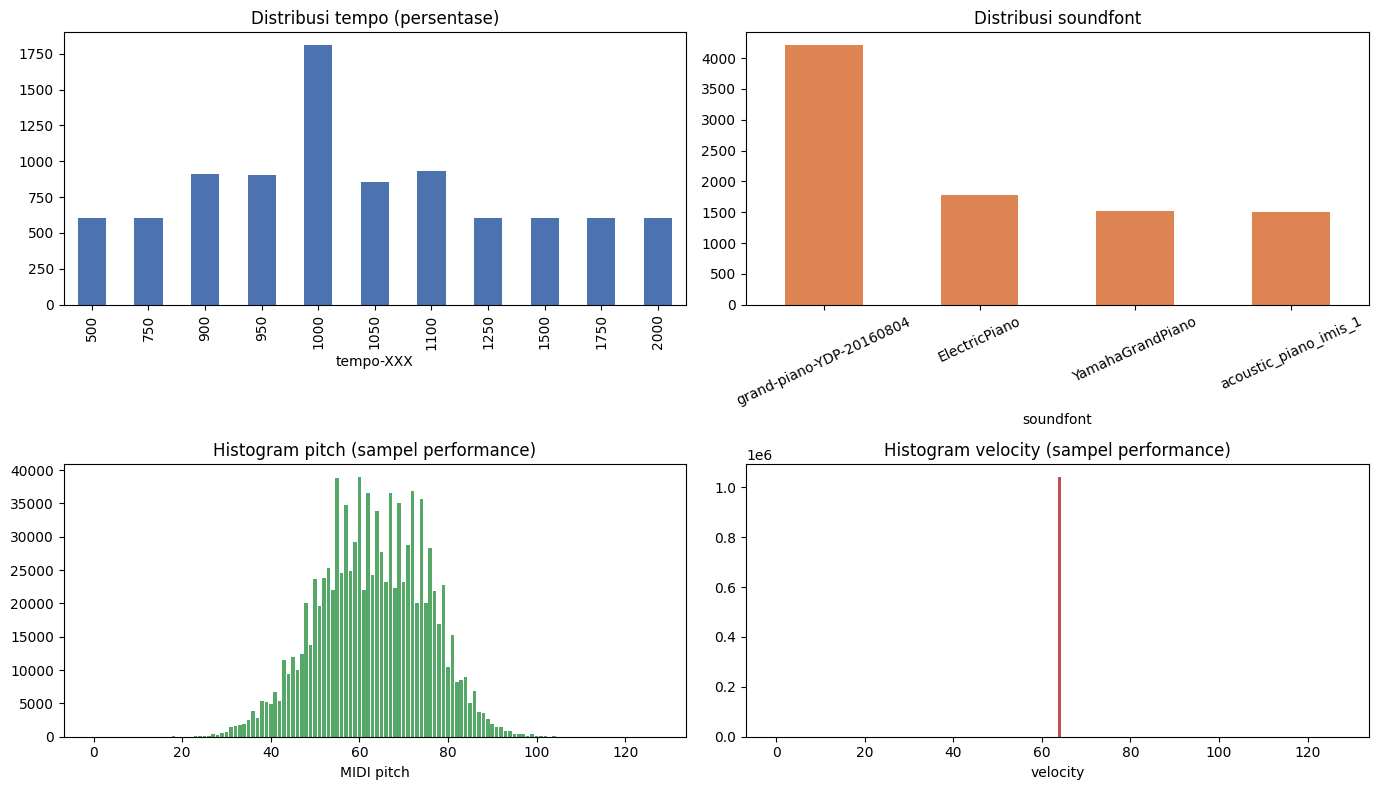

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

perf_df["tempo"].value_counts().sort_index().plot.bar(ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Distribusi tempo (persentase)")
axes[0, 0].set_xlabel("tempo-XXX")

perf_df["soundfont"].value_counts().plot.bar(ax=axes[0, 1], color="#DD8452")
axes[0, 1].set_title("Distribusi soundfont")
axes[0, 1].tick_params(axis="x", rotation=25)

axes[1, 0].bar(np.arange(128), pitch_hist_total, color="#55A868")
axes[1, 0].set_title("Histogram pitch (sampel performance)")
axes[1, 0].set_xlabel("MIDI pitch")

axes[1, 1].bar(np.arange(128), vel_hist_total, color="#C44E52")
axes[1, 1].set_title("Histogram velocity (sampel performance)")
axes[1, 1].set_xlabel("velocity")

plt.tight_layout()
plt.savefig(FIG / "02_tempo_soundfont_pitch.png", dpi=120, bbox_inches="tight")
plt.show()

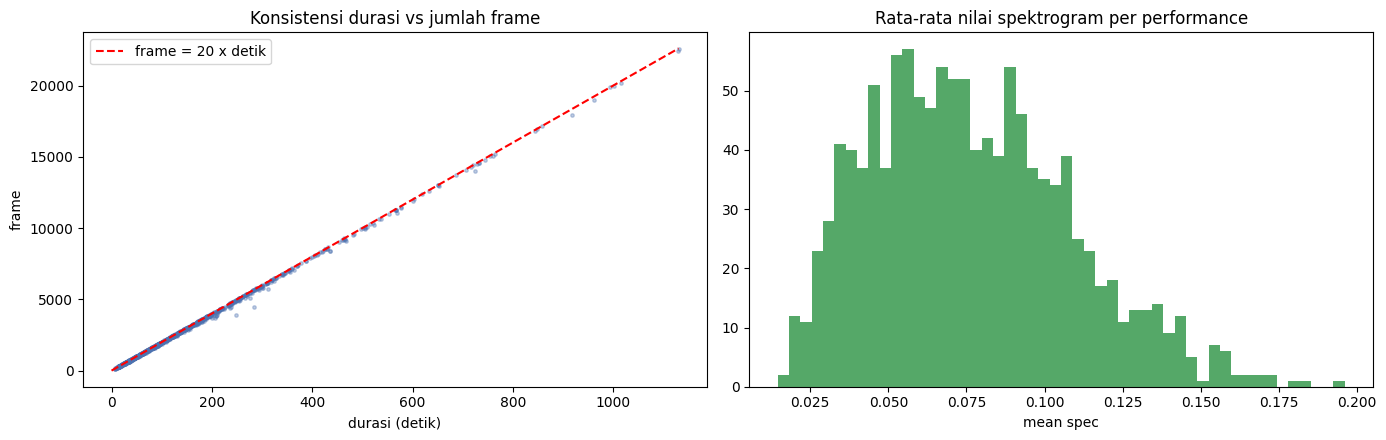

Korelasi n_notes vs durasi : 0.755
Korelasi n_frames vs durasi : 1.0
Frame/detik (median)        : 19.76


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(perf_stats["duration_s"], perf_stats["n_frames"], s=6, alpha=0.35, color="#4C72B0")
maxd = perf_stats["duration_s"].max()
xx = np.linspace(0, maxd, 100)
axes[0].plot(xx, xx * FPS, "r--", label="frame = 20 x detik")
axes[0].set_title("Konsistensi durasi vs jumlah frame")
axes[0].set_xlabel("durasi (detik)")
axes[0].set_ylabel("frame")
axes[0].legend()

axes[1].hist(perf_stats["spec_mean"], bins=50, color="#55A868")
axes[1].set_title("Rata-rata nilai spektrogram per performance")
axes[1].set_xlabel("mean spec")

plt.tight_layout()
plt.savefig(FIG / "03_konsistensi_dan_spektrum.png", dpi=120, bbox_inches="tight")
plt.show()

print("Korelasi n_notes vs durasi :", round(float(perf_stats["n_notes"].corr(perf_stats["duration_s"])), 3))
print("Korelasi n_frames vs durasi :", round(float(perf_stats["n_frames"].corr(perf_stats["duration_s"])), 3))
print("Frame/detik (median)        :", round(float((perf_stats["n_frames"] / perf_stats["duration_s"]).median()), 2))

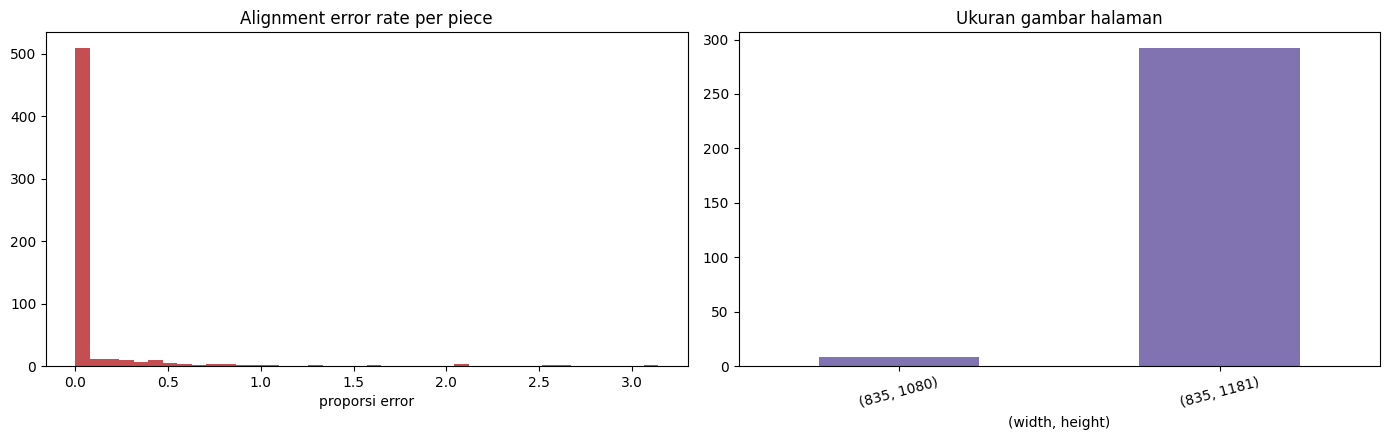

Alignment error rate: median = 0.0016 | p90 = 0.1922
Ink ratio gambar: median = 0.0884


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

err = manifest["alignment_error_rate"].dropna()
axes[0].hist(err, bins=40, color="#C44E52")
axes[0].set_title("Alignment error rate per piece")
axes[0].set_xlabel("proporsi error")

img_stats.groupby(["width", "height"]).size().plot.bar(ax=axes[1], color="#8172B2")
axes[1].set_title("Ukuran gambar halaman")
axes[1].set_xlabel("(width, height)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(FIG / "04_alignment_dan_ukuran_gambar.png", dpi=120, bbox_inches="tight")
plt.show()

print("Alignment error rate: median =", round(float(err.median()), 4), "| p90 =", round(float(err.quantile(0.9)), 4))
print("Ink ratio gambar: median =", round(float(img_stats["ink_ratio"].median()), 4))

stats["n_notes_median"] = int(perf_stats["n_notes"].median())
stats["duration_s_median"] = float(perf_stats["duration_s"].median())
stats["pages_median"] = float(manifest.loc[manifest.pages > 0, "pages"].median())
stats["pages_max"] = int(manifest["pages"].max())
stats["alignment_error_median"] = float(err.median())

## 5. Pemeriksaan Isi Array dan Alignment
Memeriksa satu contoh nyata: gambar halaman, spektrogram, piano roll, MuNG, dan keterkaitan notehead ke event audio.

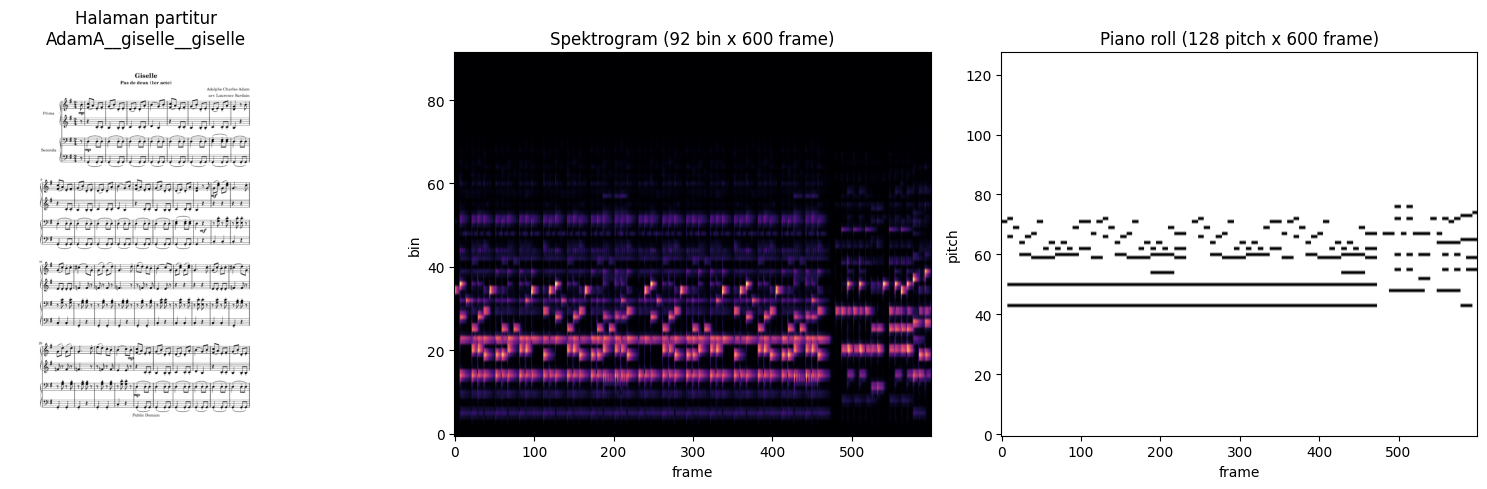

Contoh piece : AdamA__giselle__giselle
Contoh perf  : AdamA__giselle__giselle_tempo-1000_acoustic_piano_imis_1
notes shape  : (541, 5) | spec: (92, 1433) | roll: (128, 1433)


In [10]:
example = manifest[(manifest["has_mung"]) & (manifest["n_features_complete"] > 0) & (manifest["pages"] > 0)].iloc[0]
ex_piece = example["piece"]
ex_perfs = perf_df[(perf_df["piece"] == ex_piece) & (perf_df["complete_features"])].copy()
ex_perfs["tempo_dist"] = (ex_perfs["tempo"].fillna(1000) - 1000).abs()
ex_perf = ex_perfs.sort_values(["tempo_dist", "tempo"]).iloc[0]
ex_sd = sorted([d for d in (BASE / ex_piece / "scores").iterdir() if d.is_dir()])[0]
ex_png = sorted((ex_sd / "img").glob("*.png"))[0]

im = Image.open(ex_png).convert("RGBA")
bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
im_gray = Image.alpha_composite(bg, im).convert("L")

spec = np.load(Path(ex_perf["features_dir"]) / f"{ex_perf['perf_name']}.flac_spec.npy")
roll = np.load(Path(ex_perf["features_dir"]) / f"{ex_perf['perf_name']}.flac_midi.npy")
notes = np.load(Path(ex_perf["features_dir"]) / f"{ex_perf['perf_name']}.flac_notes.npy")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(im_gray, cmap="gray")
axes[0].set_title(f"Halaman partitur\n{ex_piece}")
axes[0].axis("off")

axes[1].imshow(spec[:, :600], aspect="auto", origin="lower", cmap="magma")
axes[1].set_title("Spektrogram (92 bin x 600 frame)")
axes[1].set_xlabel("frame")
axes[1].set_ylabel("bin")

axes[2].imshow(roll[:, :600], aspect="auto", origin="lower", cmap="Greys")
axes[2].set_title("Piano roll (128 pitch x 600 frame)")
axes[2].set_xlabel("frame")
axes[2].set_ylabel("pitch")

plt.tight_layout()
plt.savefig(FIG / "05_contoh_modalitas.png", dpi=120, bbox_inches="tight")
plt.show()

print("Contoh piece :", ex_piece)
print("Contoh perf  :", ex_perf["perf_name"])
print("notes shape  :", notes.shape, "| spec:", spec.shape, "| roll:", roll.shape)

In [11]:
mung_path = sorted((ex_sd / "mung").glob("*.xml"))[0]
tree = ET.parse(mung_path)
noteheads = []
for obj in tree.getroot().iter("CropObject"):
    if obj.findtext("ClassName") != "notehead-full":
        continue
    data = {d.get("key"): d.text for d in obj.iter("DataItem")}
    noteheads.append({
        "id": obj.findtext("Id"),
        "top": int(obj.findtext("Top")),
        "left": int(obj.findtext("Left")),
        "width": int(obj.findtext("Width")),
        "height": int(obj.findtext("Height")),
        "pitch": int(data["midi_pitch_code"]),
        "tied": int(data["tied"]),
        "data": data,
    })

perf_name = ex_perf["perf_name"]
idx_key = f"{perf_name}_note_event_idx"
example_notehead = next((n for n in noteheads if idx_key in n["data"]), None)
if example_notehead is not None:
    idx = int(example_notehead["data"][idx_key])
    print("Notehead id        :", example_notehead["id"])
    print("Pitch di MuNG      :", example_notehead["pitch"])
    print("note_event_idx     :", idx)
    print("Baris notes.npy    :", notes[idx])
    print("Cocok pitch        :", int(notes[idx, 1]) == example_notehead["pitch"])
    print("Onset MuNG (detik) :", example_notehead["data"].get(f"{perf_name}_onset_seconds"))
    print("Onset notes (detik):", notes[idx, 0])

# verifikasi koordinat (y, x) vs MuNG
coord_path = ex_sd / "coords" / "notes_01.npy"
if coord_path.exists():
    coords = np.load(coord_path)
    centers = np.array([[n["top"] + n["height"] / 2, n["left"] + n["width"] / 2] for n in noteheads])
    if len(coords) and len(centers):
        d = np.linalg.norm(coords[:, None, :] - centers[None, :, :], axis=2)
        nearest = d.min(axis=1)
        print("coords notes_01 shape:", coords.shape)
        print("Cocok < 2px          :", int((nearest < 2).sum()), "/", len(coords))

bars_path = ex_sd / "coords" / "bars_01.npy"
if bars_path.exists():
    print("bars_01 shape        :", np.load(bars_path).shape, "(kosong = placeholder)")

Notehead id        : 0
Pitch di MuNG      : 54
note_event_idx     : 79
Baris notes.npy    : [ 9.375 54.     0.75  64.     2.   ]
Cocok pitch        : True
Onset MuNG (detik) : 9.375
Onset notes (detik): 9.375
coords notes_01 shape: (424, 2)
Cocok < 2px          : 424 / 424
bars_01 shape        : (0, 2, 2) (kosong = placeholder)


## 6. Audit Duplikasi dan Potensi Leakage
Beberapa piece merupakan varian karya yang sama (mis. `-a4` vs `-let`). Jika split dilakukan per halaman/performance, varian ini bisa bocor antar train-test. Karena itu split harus di level `work_group`.

In [12]:
grouped = manifest.groupby("work_group")["piece"].apply(list)
dups = grouped[grouped.map(len) > 1].sort_values(key=lambda s: s.map(len), ascending=False)
print("Jumlah work_group berisi >1 piece:", len(dups))
for wk, pieces in dups.head(12).items():
    print(f"- {wk} -> {pieces}")

manifest[["piece", "composer", "collection", "work_group"]].to_csv(DATA / "work_groups.csv", index=False)
stats["n_duplicate_work_groups"] = int(len(dups))

Jumlah work_group berisi >1 piece: 10
- ChopinFF__O25__chopin2502 -> ['ChopinFF__O25__a4-chopin-25-02-wfp', 'ChopinFF__O25__a4-PS-chopin-25-02-i', 'ChopinFF__O25__letter-chopin-25-02-wfp', 'ChopinFF__O25__letter-PS-chopin-25-02-i']
- BeethovenLv__O27__moonlight1 -> ['BeethovenLv__O27__moonlight1-a4', 'BeethovenLv__O27__moonlight1-let']
- BeethovenLv__O27__moonlight2 -> ['BeethovenLv__O27__moonlight2-a4', 'BeethovenLv__O27__moonlight2-let']
- BeethovenLv__O27__moonlight3 -> ['BeethovenLv__O27__moonlight3-a4', 'BeethovenLv__O27__moonlight3-let']
- ChopinFF__O10__chop1001 -> ['ChopinFF__O10__chp-10-01-a4', 'ChopinFF__O10__chp-10-01-let']
- ChopinFF__O10__chop1005 -> ['ChopinFF__O10__chp-10-05-a4', 'ChopinFF__O10__chp-10-05-let']
- ChopinFF__O28__chop2804 -> ['ChopinFF__O28__chp-28-04-a4', 'ChopinFF__O28__chp-28-04-let']
- ChopinFF__O35__chopop354scholzfi -> ['ChopinFF__O35__chp-op-35-4-scholz-fi-a4', 'ChopinFF__O35__chp-op-35-4-scholz-fi-let']
- SchumannR__O124__16berceuse -> ['SchumannR_

## 7. Pemilihan Subset dan Split
Subset 25 piece dipilih dari piece siap pakai, satu per `work_group`, dengan rotasi antar-composer agar beragam. Setiap piece diambil 4 performance (satu per soundfont, tempo terdekat 1000). Split 70/15/15 dilakukan pada level `work_group`.

In [13]:
cand = manifest[
    (manifest["n_scores"] > 0)
    & (manifest["n_performances"] > 0)
    & (manifest["n_features_complete"] > 0)
    & (manifest["pages"].between(1, 6))
    & (manifest["duration_s_canonical"].between(30, 600))
].copy()

cand = cand.sort_values(["work_group", "n_features_complete"], ascending=[True, False]).drop_duplicates("work_group")

groups_by_composer = {c: g.sample(frac=1, random_state=SEED) for c, g in cand.groupby("composer")}
composers = list(groups_by_composer)
random.Random(SEED).shuffle(composers)

selected = []
idx = 0
while len(selected) < N_SUBSET:
    added = False
    for c in composers:
        if idx < len(groups_by_composer[c]):
            selected.append(groups_by_composer[c].iloc[idx])
            added = True
            if len(selected) >= N_SUBSET:
                break
    if not added:
        break
    idx += 1

subset = pd.DataFrame(selected).drop_duplicates("piece").head(N_SUBSET).copy()
print("Kandidat awal        :", len(cand))
print("Piece terpilih       :", len(subset))
print("Composer terwakili   :", subset["composer"].nunique())
display(subset[["piece", "composer", "pages", "n_notes_canonical", "duration_s_canonical"]].head(10))

Kandidat awal        : 471
Piece terpilih       : 25
Composer terwakili   : 25


,piece,composer,pages,n_notes_canonical,duration_s_canonical
611,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI,6,1813.0,284.166553
376,GriegE__O46__02-lamortdase,GriegE,3,746.0,217.200000
373,FrobergerJJ__Suite7__Suite7,FrobergerJJ,3,443.0,122.500000
364,DussekJL__O46__Dussek_Op46_1,DussekJL,6,1197.0,126.000000
372,FischerJKF__Fischer_EratoPraeludium__Fischer_EratoPraeludium,FischerJKF,1,312.0,62.000000
279,ChopinFF__B130__TroisNouvellesEtudes_Chopin_n1,ChopinFF,3,829.0,160.800000
443,MagnenatS__variations-automne__variations-automne,MagnenatS,2,545.0,141.549754
451,MinkusLA__bayadere-acteII__bayadere-acteII,MinkusLA,2,980.0,232.718265
695,WanhalJ__O42__wanhal-rondo,WanhalJ,1,370.0,62.222160
696,Yaniewicz__leslanciers__leslanciers,Yaniewicz,1,239.0,48.837110


In [14]:
perf_ok = perf_df[perf_df["complete_features"]].copy()
perf_ok["tempo_dist"] = (perf_ok["tempo"].fillna(1000) - 1000).abs()

selected_perfs = []
for piece in subset["piece"]:
    pf = perf_ok[perf_ok["piece"] == piece].copy()
    chosen = []
    for sf in pf["soundfont"].unique():
        sub = pf[pf["soundfont"] == sf].sort_values(["tempo_dist", "tempo"])
        if len(sub):
            chosen.append(sub.iloc[0])
    if len(chosen) < N_PERF:
        used = {x["perf_name"] for x in chosen}
        rest = pf[~pf["perf_name"].isin(used)].sort_values(["tempo_dist", "tempo"])
        for _, r in rest.iterrows():
            if len(chosen) >= N_PERF:
                break
            chosen.append(r)
    selected_perfs.extend(chosen[:N_PERF])

subset_perfs = pd.DataFrame(selected_perfs).reset_index(drop=True)
print("Performance terpilih :", len(subset_perfs))
print("Performance/piece    :", subset_perfs.groupby("piece").size().describe().to_dict())
display(subset_perfs[["piece", "perf_name", "tempo", "soundfont"]].head(12))

Performance terpilih : 100
Performance/piece    : {'count': 25.0, 'mean': 4.0, 'std': 0.0, 'min': 4.0, '25%': 4.0, '50%': 4.0, '75%': 4.0, 'max': 4.0}


,piece,perf_name,tempo,soundfont
0,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__Tschaikowsky-op37.2_tempo-1000_acoustic_piano_imis_1,1000,acoustic_piano_imis_1
1,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__Tschaikowsky-op37.2_tempo-1000_ElectricPiano,1000,ElectricPiano
2,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__Tschaikowsky-op37.2_tempo-1000_grand-piano-YDP-20160804,1000,grand-piano-YDP-20160804
3,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__Tschaikowsky-op37.2_tempo-1000_YamahaGrandPiano,1000,YamahaGrandPiano
4,GriegE__O46__02-lamortdase,GriegE__O46__02-lamortdase_tempo-1000_ElectricPiano,1000,ElectricPiano
5,GriegE__O46__02-lamortdase,GriegE__O46__02-lamortdase_tempo-1000_grand-piano-YDP-20160804,1000,grand-piano-YDP-20160804
6,GriegE__O46__02-lamortdase,GriegE__O46__02-lamortdase_tempo-1050_acoustic_piano_imis_1,1050,acoustic_piano_imis_1
7,GriegE__O46__02-lamortdase,GriegE__O46__02-lamortdase_tempo-900_YamahaGrandPiano,900,YamahaGrandPiano
8,FrobergerJJ__Suite7__Suite7,FrobergerJJ__Suite7__Suite7_tempo-1000_ElectricPiano,1000,ElectricPiano
9,FrobergerJJ__Suite7__Suite7,FrobergerJJ__Suite7__Suite7_tempo-1000_grand-piano-YDP-20160804,1000,grand-piano-YDP-20160804


In [15]:
works = subset[["piece", "work_group"]].drop_duplicates().reset_index(drop=True)
n_works = len(works)
order = list(range(n_works))
random.Random(SEED).shuffle(order)
n_val = max(2, round(0.15 * n_works))
n_test = max(2, round(0.15 * n_works))
val_idx = set(order[:n_val])
test_idx = set(order[n_val:n_val + n_test])
train_idx = set(order[n_val + n_test:])

split_map = {}
for i, row in works.iterrows():
    split_map[row["piece"]] = "val" if i in val_idx else ("test" if i in test_idx else "train")

subset["split"] = subset["piece"].map(split_map)
subset_perfs["split"] = subset_perfs["piece"].map(split_map)

splits = subset[["piece", "work_group", "split"]].copy()
splits.to_csv(DATA / "splits.csv", index=False)
subset[["piece", "composer", "collection", "work_group", "pages", "duration_s_canonical", "split"]].to_csv(DATA / "subset_pieces.csv", index=False)
subset_perfs[["piece", "work_group", "perf_name", "tempo", "soundfont", "features_dir", "split"]].to_csv(DATA / "subset_performances.csv", index=False)

for a, b in combinations(["train", "val", "test"], 2):
    wa = set(splits.loc[splits["split"] == a, "work_group"])
    wb = set(splits.loc[splits["split"] == b, "work_group"])
    assert not (wa & wb), f"Leakage work_group antara {a} dan {b}"

print(splits.groupby("split").size().rename("n_piece"))
print(subset_perfs.groupby("split").size().rename("n_performance"))
display(splits)

stats["n_subset_pieces"] = int(len(subset))
stats["n_subset_perfs"] = int(len(subset_perfs))
stats["split_piece_counts"] = splits.groupby("split").size().to_dict()
stats["subset_composers"] = int(subset["composer"].nunique())

split
test      4
train    17
val       4
Name: n_piece, dtype: int64
split
test     16
train    68
val      16
Name: n_performance, dtype: int64


,piece,work_group,split
611,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__tschaikowskyop372,train
376,GriegE__O46__02-lamortdase,GriegE__O46__2lamortdase,train
373,FrobergerJJ__Suite7__Suite7,FrobergerJJ__Suite7__suite7,train
364,DussekJL__O46__Dussek_Op46_1,DussekJL__O46__dussekop461,train
372,FischerJKF__Fischer_EratoPraeludium__Fischer_EratoPraeludium,FischerJKF__Fischer_EratoPraeludium__fischereratopraeludium,train
279,ChopinFF__B130__TroisNouvellesEtudes_Chopin_n1,ChopinFF__B130__troisnouvellesetudeschopinn1,test
443,MagnenatS__variations-automne__variations-automne,MagnenatS__variations-automne__variationsautomne,test
451,MinkusLA__bayadere-acteII__bayadere-acteII,MinkusLA__bayadere-acteII__bayadereacteii,train
695,WanhalJ__O42__wanhal-rondo,WanhalJ__O42__wanhalrondo,train
696,Yaniewicz__leslanciers__leslanciers,Yaniewicz__leslanciers__leslanciers,val


## 8. Eksperimen Preprocessing Visual
Membandingkan dua pendekatan: **resize langsung ke persegi** vs **pad** (mempertahankan aspect ratio). Metrik yang dipakai: distorsi geometri dan perubahan ink ratio.

In [16]:
def load_gray(path):
    im = Image.open(path).convert("RGBA")
    bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
    return Image.alpha_composite(bg, im).convert("L")


def resize_square(im, size=IMG_SIZE):
    return im.resize((size, size), Image.BILINEAR)


def pad_square(im, size=IMG_SIZE):
    w, h = im.size
    s = min(size / w, size / h)
    nw, nh = max(1, int(round(w * s))), max(1, int(round(h * s)))
    im2 = im.resize((nw, nh), Image.BILINEAR)
    canvas = Image.new("L", (size, size), 255)
    canvas.paste(im2, ((size - nw) // 2, (size - nh) // 2))
    return canvas


def page_paths(piece):
    out = []
    sdir = BASE / piece / "scores"
    if sdir.is_dir():
        for sd in sorted([d for d in sdir.iterdir() if d.is_dir()]):
            out.extend(sorted((sd / "img").glob("*.png")))
    return out


vis_rows = []
subset_pages = []
for piece in subset["piece"]:
    subset_pages.extend(page_paths(piece))

for p in subset_pages[:120]:
    im = load_gray(p)
    arr0 = np.asarray(im)
    w, h = im.size
    ink0 = float((arr0 < 128).mean())
    r = resize_square(im)
    d = pad_square(im)
    vis_rows.append({
        "width": w,
        "height": h,
        "aspect": w / h,
        "ink_original": ink0,
        "ink_resize": float((np.asarray(r) < 128).mean()),
        "ink_pad": float((np.asarray(d) < 128).mean()),
        "distortion_resize": max(w, h) / min(w, h),
        "distortion_pad": 1.0,
    })

vis_df = pd.DataFrame(vis_rows)
display(vis_df[["aspect", "ink_original", "ink_resize", "ink_pad", "distortion_resize", "distortion_pad"]].describe().T)
print("Rata-rata perubahan ink ratio (resize):", round(float((vis_df.ink_resize - vis_df.ink_original).abs().mean()), 5))
print("Rata-rata perubahan ink ratio (pad)   :", round(float((vis_df.ink_pad - vis_df.ink_original).abs().mean()), 5))

VIS_TRANSFORM = "pad"
print("Transform dipilih:", VIS_TRANSFORM)

,count,mean,std,min,25%,50%,75%,max
aspect,61.0,0.707028,0.000000,0.707028,0.707028,0.707028,0.707028,0.707028
ink_original,61.0,0.079532,0.025591,0.018626,0.065596,0.087765,0.096726,0.118534
ink_resize,61.0,0.040767,0.016835,0.005005,0.028653,0.043179,0.052083,0.075229
ink_pad,61.0,0.024781,0.010931,0.003038,0.016852,0.026577,0.032186,0.047933
distortion_resize,61.0,1.414371,0.000000,1.414371,1.414371,1.414371,1.414371,1.414371
distortion_pad,61.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Rata-rata perubahan ink ratio (resize): 0.03876
Rata-rata perubahan ink ratio (pad)   : 0.05475
Transform dipilih: pad


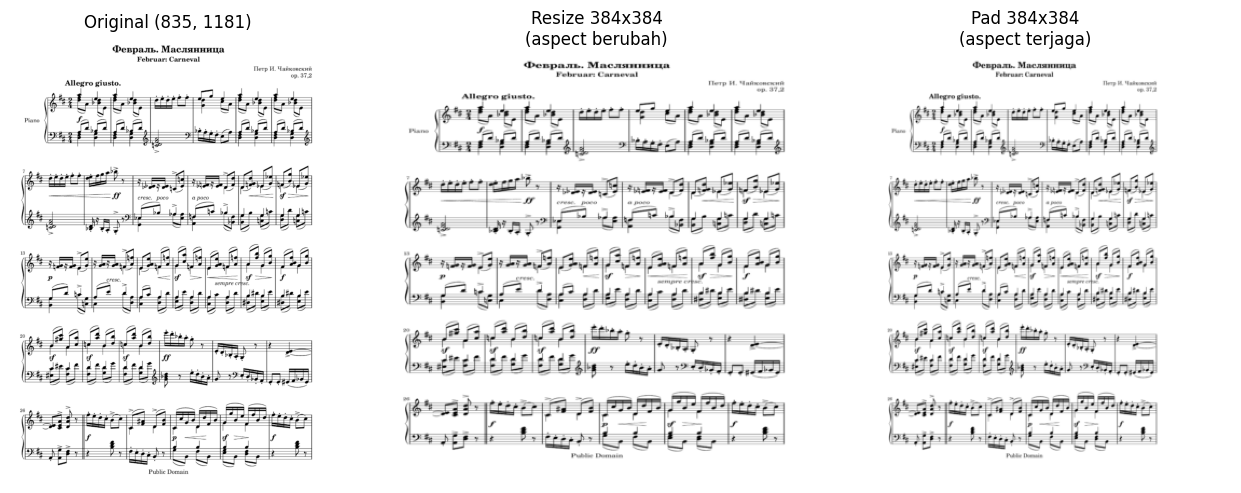

In [17]:
p0 = subset_pages[0]
im0 = load_gray(p0)
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
axes[0].imshow(im0, cmap="gray")
axes[0].set_title(f"Original {im0.size}")
axes[0].axis("off")
axes[1].imshow(resize_square(im0), cmap="gray")
axes[1].set_title(f"Resize {IMG_SIZE}x{IMG_SIZE}\n(aspect berubah)")
axes[1].axis("off")
axes[2].imshow(pad_square(im0), cmap="gray")
axes[2].set_title(f"Pad {IMG_SIZE}x{IMG_SIZE}\n(aspect terjaga)")
axes[2].axis("off")
plt.tight_layout()
plt.savefig(FIG / "06_eksperimen_visual.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Eksperimen Preprocessing Audio
Membandingkan normalisasi **global** vs **per-bin**, lalu memilih panjang segmen. Spektrogram adalah representasi audio utama; piano roll dipakai sebagai pembanding.

In [18]:
sample_train = subset_perfs[subset_perfs["split"] == "train"].head(12)
spec_list = []
for _, r in sample_train.iterrows():
    s = np.load(Path(r["features_dir"]) / f"{r['perf_name']}.flac_spec.npy")
    spec_list.append(s.T.astype(np.float32))
all_spec = np.concatenate(spec_list, axis=0)

g_mean = float(all_spec.mean())
g_std = float(all_spec.std())
pb_mean = all_spec.mean(axis=0)
pb_std = all_spec.std(axis=0)
pb_std[pb_std < 1e-6] = 1.0

norm_rows = []
for mode in ["global", "per-bin"]:
    devs = []
    clips = []
    for s in spec_list:
        norm = (s - g_mean) / g_std if mode == "global" else (s - pb_mean) / pb_std
        devs.append(float(np.abs(norm.std(axis=0) - 1).mean()))
        clips.append(float((np.abs(norm) > 5).mean()))
    norm_rows.append({"mode": mode, "mean_abs_std_dev": float(np.mean(devs)), "clip_rate_gt5": float(np.mean(clips))})

norm_df = pd.DataFrame(norm_rows)
display(norm_df)
AUDIO_NORM = "per-bin"
print("Normalisasi dipilih:", AUDIO_NORM)

,mode,mean_abs_std_dev,clip_rate_gt5
0,global,0.634354,0.004714
1,per-bin,0.380894,0.002950


Normalisasi dipilih: per-bin


In [19]:
seg_rows = []
for L in [40, 100, 200]:
    total = 0
    per = []
    cov_num = 0
    cov_den = 0
    for _, r in subset_perfs.iterrows():
        F = int(np.load(Path(r["features_dir"]) / f"{r['perf_name']}.flac_spec.npy", mmap_mode="r").shape[1])
        nseg = F // L
        total += nseg
        per.append(nseg)
        cov_num += nseg * L
        cov_den += F
    seg_rows.append({
        "segment_frames": L,
        "seconds": L / FPS,
        "total_segments": total,
        "min_per_perf": int(min(per)) if per else 0,
        "median_per_perf": int(np.median(per)) if per else 0,
        "coverage": cov_num / cov_den if cov_den else 0,
        "cache_MB_float16": total * L * 92 * 2 / 1e6,
    })

seg_df = pd.DataFrame(seg_rows)
display(seg_df)
SEG_FRAMES = 100
print("Panjang segmen dipilih:", SEG_FRAMES, "frame =", SEG_FRAMES / FPS, "detik")

,segment_frames,seconds,total_segments,min_per_perf,median_per_perf,coverage,cache_MB_float16
0,40,2.0,7161,14,62,0.994286,52.70496
1,100,5.0,2844,5,25,0.987205,52.32960
2,200,10.0,1401,2,12,0.972626,51.55680


Panjang segmen dipilih: 100 frame = 5.0 detik


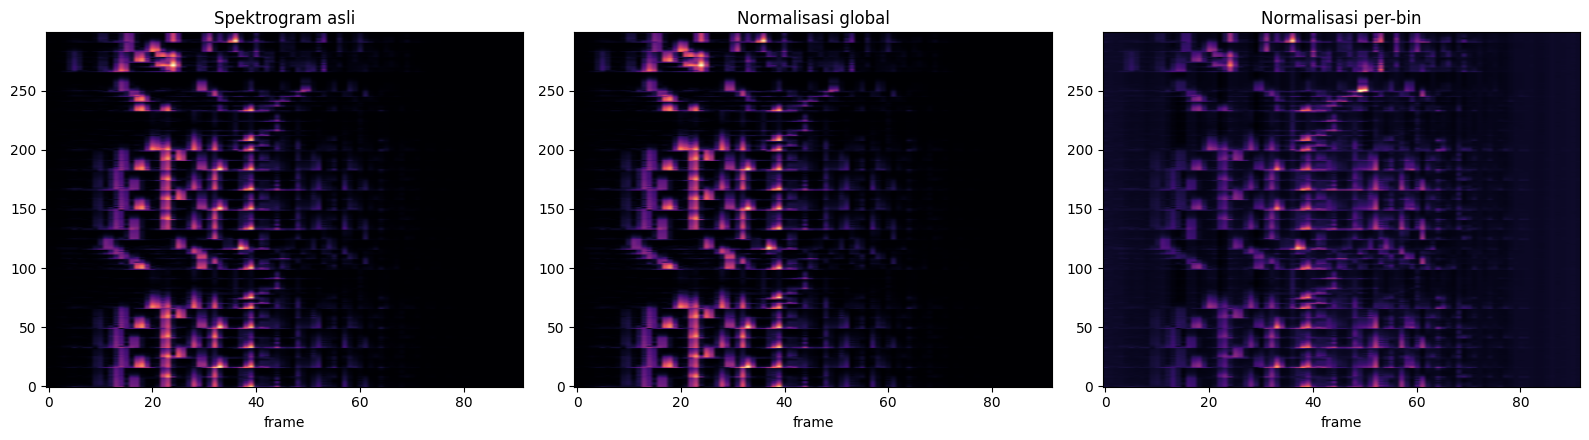

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].imshow(spec_list[0][:300], aspect="auto", origin="lower", cmap="magma")
axes[0].set_title("Spektrogram asli")
axes[0].set_xlabel("frame")
axes[1].imshow(((spec_list[0] - g_mean) / g_std)[:300], aspect="auto", origin="lower", cmap="magma")
axes[1].set_title("Normalisasi global")
axes[1].set_xlabel("frame")
axes[2].imshow(((spec_list[0] - pb_mean) / pb_std)[:300], aspect="auto", origin="lower", cmap="magma")
axes[2].set_title("Normalisasi per-bin")
axes[2].set_xlabel("frame")
plt.tight_layout()
plt.savefig(FIG / "07_eksperimen_normalisasi_audio.png", dpi=120, bbox_inches="tight")
plt.show()

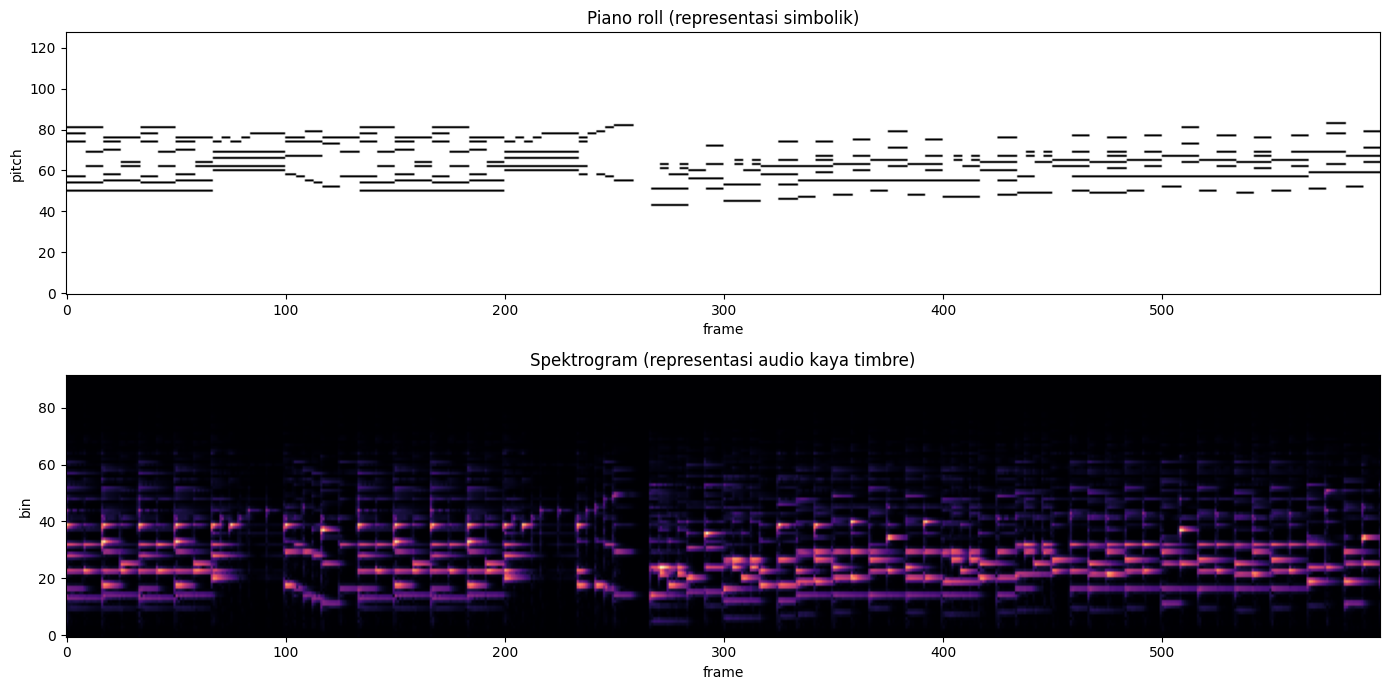

In [21]:
roll_sample = np.load(Path(sample_train.iloc[0]["features_dir"]) / f"{sample_train.iloc[0]['perf_name']}.flac_midi.npy")
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].imshow(roll_sample[:, :600], aspect="auto", origin="lower", cmap="Greys")
axes[0].set_title("Piano roll (representasi simbolik)")
axes[0].set_ylabel("pitch")
axes[0].set_xlabel("frame")
axes[1].imshow(spec_list[0][:600].T, aspect="auto", origin="lower", cmap="magma")
axes[1].set_title("Spektrogram (representasi audio kaya timbre)")
axes[1].set_ylabel("bin")
axes[1].set_xlabel("frame")
plt.tight_layout()
plt.savefig(FIG / "08_spec_vs_pianoroll.png", dpi=120, bbox_inches="tight")
plt.show()

## 10. Membuat Artefak Siap Training
Statistik normalisasi **hanya dihitung dari train**. Setelah itu barulah val/test ditransformasikan.

In [22]:
# statistik gambar dari train
train_pages = []
for piece in subset.loc[subset["split"] == "train", "piece"]:
    train_pages.extend(page_paths(piece))

train_imgs = []
for p in train_pages:
    im = pad_square(load_gray(p), IMG_SIZE) if VIS_TRANSFORM == "pad" else resize_square(load_gray(p), IMG_SIZE)
    train_imgs.append(np.asarray(im, dtype=np.float32) / 255.0)

train_imgs = np.stack(train_imgs)
IMG_MEAN = float(train_imgs.mean())
IMG_STD = float(train_imgs.std())
print("Image stats (train only): mean =", round(IMG_MEAN, 4), "| std =", round(IMG_STD, 4))

# statistik spektrogram dari train
sum_bins = np.zeros(92, dtype=np.float64)
sumsq_bins = np.zeros(92, dtype=np.float64)
count_frames = 0
for _, r in subset_perfs[subset_perfs["split"] == "train"].iterrows():
    s = np.load(Path(r["features_dir"]) / f"{r['perf_name']}.flac_spec.npy").T.astype(np.float64)
    sum_bins += s.sum(axis=0)
    sumsq_bins += (s * s).sum(axis=0)
    count_frames += s.shape[0]

SPEC_MEAN = sum_bins / count_frames
SPEC_STD = np.sqrt(np.maximum(sumsq_bins / count_frames - SPEC_MEAN ** 2, 0))
SPEC_STD[SPEC_STD < 1e-6] = 1.0
print("Spec stats (train only): frames =", count_frames, "| mean range =", round(float(SPEC_MEAN.min()), 4), "..", round(float(SPEC_MEAN.max()), 4))

norm_stats = {
    "image": {"transform": VIS_TRANSFORM, "size": IMG_SIZE, "mean": IMG_MEAN, "std": IMG_STD},
    "audio": {
        "normalization": AUDIO_NORM,
        "segment_frames": SEG_FRAMES,
        "fps": FPS,
        "spec_mean": SPEC_MEAN.tolist(),
        "spec_std": SPEC_STD.tolist(),
    },
    "split": "group_by_work_group",
    "seed": SEED,
}
with open(PROC / "norm_stats.json", "w", encoding="utf-8") as f:
    json.dump(norm_stats, f, indent=2)
print("Saved:", PROC / "norm_stats.json")

Image stats (train only): mean = 0.943 | std = 0.1417


Spec stats (train only): frames = 216320 | mean range = 0.0023 .. 0.1817
Saved: C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT\data\processed\norm_stats.json


In [23]:
score_index_all = []
audio_index_all = []

for split in ["train", "val", "test"]:
    arrs = []
    rows = []
    for piece in subset.loc[subset["split"] == split, "piece"]:
        for page_num, p in enumerate(page_paths(piece), start=1):
            im = pad_square(load_gray(p), IMG_SIZE) if VIS_TRANSFORM == "pad" else resize_square(load_gray(p), IMG_SIZE)
            arr = (np.asarray(im, dtype=np.float32) / 255.0 - IMG_MEAN) / IMG_STD
            arrs.append(arr.astype(np.float16)[..., None])
            rows.append({
                "page_id": f"{piece}__p{page_num:02d}",
                "piece": piece,
                "work_group": subset.loc[subset["piece"] == piece, "work_group"].iloc[0],
                "split": split,
                "page_num": page_num,
                "path": str(p),
            })
    np.save(PROC / f"score_pages_{split}.npy", np.stack(arrs))
    idx = pd.DataFrame(rows)
    idx.to_csv(PROC / f"score_index_{split}.csv", index=False)
    score_index_all.append(idx)
    print(f"score {split:5s}: {len(idx):4d} halaman")

score_index = pd.concat(score_index_all, ignore_index=True)
score_index.to_csv(PROC / "score_index.csv", index=False)

score train:   44 halaman
score val  :    8 halaman


score test :    9 halaman


In [24]:
for split in ["train", "val", "test"]:
    arrs = []
    rows = []
    for _, r in subset_perfs[subset_perfs["split"] == split].iterrows():
        s = np.load(Path(r["features_dir"]) / f"{r['perf_name']}.flac_spec.npy").T.astype(np.float32)
        s = np.clip((s - SPEC_MEAN) / SPEC_STD, -5, 5)
        nseg = s.shape[0] // SEG_FRAMES
        if nseg == 0:
            seg = np.zeros((SEG_FRAMES, 92), dtype=np.float32)
            seg[: s.shape[0]] = s
            arrs.append(seg.astype(np.float16))
            rows.append({
                "segment_id": f"{r['perf_name']}__s0000",
                "piece": r["piece"],
                "work_group": r["work_group"],
                "split": split,
                "perf_name": r["perf_name"],
                "tempo": int(r["tempo"]) if pd.notna(r["tempo"]) else None,
                "soundfont": r["soundfont"],
                "start_frame": 0,
                "end_frame": int(s.shape[0]),
            })
            continue
        for i in range(nseg):
            arrs.append(s[i * SEG_FRAMES:(i + 1) * SEG_FRAMES].astype(np.float16))
            rows.append({
                "segment_id": f"{r['perf_name']}__s{i:04d}",
                "piece": r["piece"],
                "work_group": r["work_group"],
                "split": split,
                "perf_name": r["perf_name"],
                "tempo": int(r["tempo"]) if pd.notna(r["tempo"]) else None,
                "soundfont": r["soundfont"],
                "start_frame": i * SEG_FRAMES,
                "end_frame": (i + 1) * SEG_FRAMES,
            })
    np.save(PROC / f"audio_segments_{split}.npy", np.stack(arrs))
    idx = pd.DataFrame(rows)
    idx.to_csv(PROC / f"audio_index_{split}.csv", index=False)
    audio_index_all.append(idx)
    print(f"audio {split:5s}: {len(idx):4d} segmen")

audio_index = pd.concat(audio_index_all, ignore_index=True)
audio_index.to_csv(PROC / "audio_index.csv", index=False)

audio train: 2138 segmen
audio val  :  226 segmen
audio test :  480 segmen


In [25]:
rng_pairs = np.random.default_rng(SEED)
pairs_all = []

for split in ["train", "val", "test"]:
    pages = score_index[score_index["split"] == split].reset_index(drop=True)
    segs = audio_index[audio_index["split"] == split].reset_index(drop=True)
    rows = []
    for _, page in pages.iterrows():
        pos = segs[segs["piece"] == page["piece"]].reset_index(drop=True)
        if len(pos):
            k = min(PAIRS_PER_PAGE, len(pos))
            for j in rng_pairs.choice(len(pos), size=k, replace=False):
                a = pos.iloc[j]
                rows.append({
                    "score_page_id": page["page_id"],
                    "audio_segment_id": a["segment_id"],
                    "label": 1,
                    "piece": page["piece"],
                    "work_group": page["work_group"],
                    "split": split,
                })
        neg = segs[segs["piece"] != page["piece"]].reset_index(drop=True)
        if len(neg):
            k = min(PAIRS_PER_PAGE, len(neg))
            for j in rng_pairs.choice(len(neg), size=k, replace=False):
                a = neg.iloc[j]
                rows.append({
                    "score_page_id": page["page_id"],
                    "audio_segment_id": a["segment_id"],
                    "label": 0,
                    "piece": page["piece"],
                    "work_group": page["work_group"],
                    "split": split,
                })
    df = pd.DataFrame(rows)
    df["pair_id"] = [f"{split}_{i:06d}" for i in range(len(df))]
    df.to_csv(PROC / f"pairs_{split}.csv", index=False)
    pairs_all.append(df)
    print(f"pairs {split:5s}: {len(df):4d} (positif={int((df.label==1).sum())}, negatif={int((df.label==0).sum())})")

pairs = pd.concat(pairs_all, ignore_index=True)
pairs.to_csv(PROC / "pairs.csv", index=False)

pairs train:  704 (positif=352, negatif=352)
pairs val  :  128 (positif=64, negatif=64)
pairs test :  144 (positif=72, negatif=72)


## 11. Verifikasi Artefak Siap Training
Memuat ulang artefak dan memastikan tidak ada NaN/Inf, split disjoint, label seimbang, dan setiap pasangan merujuk ke ID yang valid.

In [26]:
checks = []


def add_check(name, ok, detail=""):
    checks.append({"check": name, "status": "PASS" if ok else "FAIL", "detail": detail})


score_arrays = {}
audio_arrays = {}
for split in ["train", "val", "test"]:
    sc = np.load(PROC / f"score_pages_{split}.npy")
    au = np.load(PROC / f"audio_segments_{split}.npy")
    sc_idx = pd.read_csv(PROC / f"score_index_{split}.csv")
    au_idx = pd.read_csv(PROC / f"audio_index_{split}.csv")
    score_arrays[split] = (sc, sc_idx)
    audio_arrays[split] = (au, au_idx)
    add_check(f"{split}: jumlah score = index", len(sc) == len(sc_idx), f"{len(sc)} vs {len(sc_idx)}")
    add_check(f"{split}: jumlah audio = index", len(au) == len(au_idx), f"{len(au)} vs {len(au_idx)}")
    add_check(f"{split}: score finite", bool(np.isfinite(sc).all()))
    add_check(f"{split}: audio finite", bool(np.isfinite(au).all()))

# split disjoint
for a, b in combinations(["train", "val", "test"], 2):
    wa = set(score_arrays[a][1]["work_group"])
    wb = set(score_arrays[b][1]["work_group"])
    add_check(f"split {a} vs {b} disjoint", not (wa & wb))

# pasangan valid + seimbang
for split in ["train", "val", "test"]:
    p = pd.read_csv(PROC / f"pairs_{split}.csv")
    sc_idx = score_arrays[split][1]
    au_idx = audio_arrays[split][1]
    valid_sc = set(sc_idx["page_id"])
    valid_au = set(au_idx["segment_id"])
    add_check(f"{split}: semua page valid", bool(p["score_page_id"].isin(valid_sc).all()))
    add_check(f"{split}: semua segment valid", bool(p["audio_segment_id"].isin(valid_au).all()))
    n_pos = int((p["label"] == 1).sum())
    n_neg = int((p["label"] == 0).sum())
    add_check(f"{split}: ada positif & negatif", n_pos > 0 and n_neg > 0, f"pos={n_pos}, neg={n_neg}")
    add_check(f"{split}: rasio label seimbang", abs(n_pos - n_neg) <= max(10, 0.1 * len(p)), f"{n_pos}/{n_neg}")

checks_df = pd.DataFrame(checks)
display(checks_df)
print("Total check:", len(checks_df), "| FAIL:", int((checks_df.status == "FAIL").sum()))

,check,status,detail
0,train: jumlah score = index,PASS,44 vs 44
1,train: jumlah audio = index,PASS,2138 vs 2138
2,train: score finite,PASS,
3,train: audio finite,PASS,
4,val: jumlah score = index,PASS,8 vs 8
5,val: jumlah audio = index,PASS,226 vs 226
6,val: score finite,PASS,
7,val: audio finite,PASS,
8,test: jumlah score = index,PASS,9 vs 9
9,test: jumlah audio = index,PASS,480 vs 480


Total check: 27 | FAIL: 0


In [27]:
# demo batch siap training
split = "train"
sc, sc_idx = score_arrays[split]
au, au_idx = audio_arrays[split]
p = pd.read_csv(PROC / f"pairs_{split}.csv")
page_pos = {pid: i for i, pid in enumerate(sc_idx["page_id"])}
seg_pos = {sid: i for i, sid in enumerate(au_idx["segment_id"])}

sample_pairs = p.sample(4, random_state=SEED)
batch_scores = np.stack([sc[page_pos[x]] for x in sample_pairs["score_page_id"]])
batch_audio = np.stack([au[seg_pos[x]] for x in sample_pairs["audio_segment_id"]])
print("Score batch :", batch_scores.shape, batch_scores.dtype)
print("Audio batch :", batch_audio.shape, batch_audio.dtype)
print("Labels      :", sample_pairs["label"].tolist())
display(sample_pairs[["score_page_id", "audio_segment_id", "label"]])

Score batch : (4, 384, 384, 1) float16
Audio batch : (4, 100, 92) float16
Labels      : [0, 1, 0, 1]


,score_page_id,audio_segment_id,label
296,FischerJKF__Fischer_EratoPraeludium__Fischer_EratoPraeludium__p01,BachCPE__cpe-bach-rondo__cpe-bach-rondo_tempo-950_YamahaGrandPiano__s0063,0
81,TchaikovskyPI__O37__Tschaikowsky-op37.2__p06,TchaikovskyPI__O37__Tschaikowsky-op37.2_tempo-1000_YamahaGrandPiano__s0017,1
77,TchaikovskyPI__O37__Tschaikowsky-op37.2__p05,HandelGF__Aylesford__10-menuetii_tempo-1000_grand-piano-YDP-20160804__s0004,0
208,DussekJL__O46__Dussek_Op46_1__p02,DussekJL__O46__Dussek_Op46_1_tempo-1000_YamahaGrandPiano__s0021,1


In [28]:
summary = {
    "subset_pieces": int(len(subset)),
    "subset_performances": int(len(subset_perfs)),
    "score_pages_total": int(len(score_index)),
    "audio_segments_total": int(len(audio_index)),
    "pairs_total": int(len(pairs)),
    "split_pieces": splits.groupby("split").size().to_dict(),
    "split_pages": score_index.groupby("split").size().to_dict(),
    "split_segments": audio_index.groupby("split").size().to_dict(),
    "split_pairs": pairs.groupby("split").size().to_dict(),
    "image_shape": list(score_arrays["train"][0].shape[1:]),
    "audio_shape": list(audio_arrays["train"][0].shape[1:]),
    "image_dtype": str(score_arrays["train"][0].dtype),
    "audio_dtype": str(audio_arrays["train"][0].dtype),
    "checks_total": int(len(checks_df)),
    "checks_fail": int((checks_df.status == "FAIL").sum()),
}
with open(PROC / "preprocess_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
display(pd.DataFrame([summary]).T.rename(columns={0: "value"}))

,value
subset_pieces,25
subset_performances,100
score_pages_total,61
audio_segments_total,2844
pairs_total,976
split_pieces,"{'test': 4, 'train': 17, 'val': 4}"
split_pages,"{'test': 9, 'train': 44, 'val': 8}"
split_segments,"{'test': 480, 'train': 2138, 'val': 226}"
split_pairs,"{'test': 144, 'train': 704, 'val': 128}"
image_shape,"[384, 384, 1]"


## 12. Ringkasan Temuan
- Dataset berisi 697 folder piece; 600 siap dipakai (score + fitur lengkap). Varian `no-audio` tidak menyimpan file audio mentah, sehingga modalitas audio memakai `spec.npy` (dan opsional `midi.npy`).
- Distribusi composer sangat tidak seimbang (Bach mendominasi). Panjang piece, jumlah halaman, dan durasi sangat bervariasi.
- Terdapat varian karya yang sama (mis. `-a4` vs `-let`), sehingga split wajib di level `work_group`.
- Preprocessing visual memakai **pad** agar aspect ratio notasi terjaga; audio memakai **z-score per-bin** dan segmen **5 detik**.
- Artefak sudah diverifikasi: tidak ada NaN/Inf, split disjoint, label seimbang, dan ID pasangan valid.
- Pasangan positif bersifat piece-level; belum ada alignment temporal note-per-note.

In [29]:
methodology = f"""# Metodologi Dataset

## 1. Sumber Dataset

Dataset yang digunakan adalah **MSMD (Multimodal Sheet Music Dataset)** karya Dorfer et al. (2018), dalam varian *augmented* `msmd_aug_v1-1_no-audio`. Dataset ini berisi partitur piano klasik, performance MIDI, dan fitur turunan audio yang saling terhubung. Varian yang dipakai **tidak menyertakan file audio mentah** (`.flac`/`.wav`); modalitas audio direpresentasikan oleh spektrogram dan piano roll yang sudah dihitung.

## 2. Jumlah dan Struktur Data

- Total folder piece: **{stats['n_total_pieces']}**
- Piece dengan score: **{stats['n_score_pieces']}**
- Piece dengan performance: **{stats['n_perf_pieces']}**
- Piece dengan score + performance: **{stats['n_both_pieces']}**
- Piece siap pakai (score + 5 fitur lengkap): **{stats['n_ready_pieces']}**
- Total folder performance: **{stats['n_perf_dirs']}**
- Performance dengan 5 fitur lengkap: **{stats['n_complete_perfs']}**
- Halaman partitur (PNG): **{stats['n_pages']}**
- Jumlah composer: **{stats['n_composers']}**

Setiap piece memiliki struktur:

```
<piece>/
  *.ly, *.norm.ly, *.midi, meta.yml
  scores/<piece>_ly/
    *.pdf, img/*.png, coords/*.npy, mung/*.xml
  performances/<piece>_tempo-XXX_<soundfont>/
    *.midi, features/*.flac_{{notes,onsets,durations,midi,spec}}.npy
```

## 3. Fitur dan Representasi

- **Visual:** gambar halaman partitur (RGBA, umumnya 835x1181), notasi graph MuNG, dan koordinat notehead.
- **Audio:** `spec.npy` (92 bin log-filterbank x frame, 20 fps), `midi.npy` (128 pitch x frame), `notes.npy` (onset, pitch, durasi, velocity, voice), `onsets.npy`, dan `durations.npy`.
- **Simbolik:** file MIDI dan sumber LilyPond.

## 4. Target/Label

Dataset tidak memiliki kolom target eksplisit. Target diturunkan dari struktur folder:

- `piece_id` sebagai kelas utama untuk tugas pencocokan/retrieval.
- `composer` sebagai label sekunder.
- Label biner pasangan: `1` jika partitur dan audio berasal dari piece yang sama, `0` jika berbeda.

## 5. Distribusi dan Karakteristik

- Jumlah composer: **{stats['n_composers']}**, dengan distribusi sangat tidak seimbang (Bach mendominasi).
- Jumlah work group: **{stats['n_work_groups']}**; terdapat **{stats['n_duplicate_work_groups']}** work group berisi lebih dari satu piece (varian/encoding karya yang sama).
- Median halaman per piece: **{stats['pages_median']:.0f}** (maksimum **{stats['pages_max']}**).
- Median note per performance (sampel 1.200): **{stats['n_notes_median']}**.
- Median durasi performance (sampel 1.200): **{stats['duration_s_median']/60:.1f} menit**.
- Frame rate fitur audio: **20 fps**; jumlah frame konsisten dengan durasi.
- Median alignment error rate: **{stats['alignment_error_median']:.4f}**.

## 6. Keterbatasan

1. Tidak ada file audio mentah; audio hanya tersedia sebagai fitur turunan.
2. Frame rate 20 fps; `onsets` dan `durations` dalam frame, bukan detik.
3. Koordinat `coords` memakai `(y, x)`, tidak lengkap, dan `bars_*.npy` kosong.
4. Flag `aligned_well` dan `processed` bernilai `false` untuk seluruh piece sehingga tidak dapat dipakai sebagai filter kualitas.
5. Sebagian score tidak memiliki MuNG; sebagian performance tidak memiliki fitur lengkap.
6. Performance dari piece yang sama bukan sampel independen.

## 7. Subset dan Split

Subset yang diproses: **{stats['n_subset_pieces']} piece**, **{stats['n_subset_perfs']} performance** (4 performance per piece: satu per soundfont, tempo terdekat 1000), berasal dari **{stats['subset_composers']} composer**. Split dilakukan pada level `work_group` dengan proporsi 70/15/15:

{json.dumps(stats['split_piece_counts'], indent=2)}

Split group-level mencegah kebocoran varian karya yang sama antar train/val/test.

## 8. Preprocessing

- **Visual:** konversi RGBA ke grayscale (composite atas latar putih), **pad** ke 384x384 agar aspect ratio terjaga, lalu standardisasi memakai mean/std train.
- **Audio:** `spec.npy` ditranspose ke (frame, 92), dinormalisasi **z-score per-bin** memakai statistik train, di-clip ke [-5, 5], lalu dipotong menjadi segmen **5 detik (100 frame)**.
- **Pencegahan leakage:** statistik normalisasi hanya dihitung dari train; split dilakukan sebelum preprocessing; negatif sampling hanya dari piece lain di split yang sama.

## 9. Artefak

- `data/manifest_all_pieces.csv`
- `data/subset_pieces.csv`, `data/splits.csv`
- `data/processed/norm_stats.json`
- `data/processed/score_pages_{{train,val,test}}.npy` + `score_index.csv`
- `data/processed/audio_segments_{{train,val,test}}.npy` + `audio_index.csv`
- `data/processed/pairs_{{train,val,test}}.csv`
- `data/processed/preprocess_summary.json`

## 10. Hasil Verifikasi

- Total check: **{summary['checks_total']}**, gagal: **{summary['checks_fail']}**
- Score tensor: `{summary['image_shape']}` ({summary['image_dtype']})
- Audio tensor: `{summary['audio_shape']}` ({summary['audio_dtype']})
- Total halaman: **{summary['score_pages_total']}**, segmen audio: **{summary['audio_segments_total']}**, pasangan: **{summary['pairs_total']}**
"""

with open(REP / "methodology_dataset.md", "w", encoding="utf-8") as f:
    f.write(methodology)

with open(DATA / "eda_stats.json", "w", encoding="utf-8") as f:
    json.dump({**stats, **summary}, f, indent=2)

print("Saved:", REP / "methodology_dataset.md")
print("Saved:", DATA / "eda_stats.json")

files = sorted(PROC.glob("*"))
for f in files:
    print(f"{f.name:35s} {f.stat().st_size/1e6:8.2f} MB")

Saved: C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT\reports\methodology_dataset.md
Saved: C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT\data\eda_stats.json
audio_index.csv                         0.70 MB
audio_index_test.csv                    0.13 MB
audio_index_train.csv                   0.52 MB
audio_index_val.csv                     0.06 MB
audio_segments_test.npy                 8.83 MB
audio_segments_train.npy               39.34 MB
audio_segments_val.npy                  4.16 MB
norm_stats.json                         0.01 MB
pairs.csv                               0.19 MB
pairs_test.csv                          0.03 MB
pairs_train.csv                         0.14 MB
pairs_val.csv                           0.03 MB
preprocess_summary.json                 0.00 MB
score_index.csv                         0.02 MB
score_index_test.csv                    0.00 MB
score_index_train.csv                   0.01 MB
score_index_val.csv                  